In [1]:
import os
import yaml

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import cartopy.crs as ccrs
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
from datetime import datetime

from io_utils import load_processed_datasets
from plotting.labels import format_forecast_titles
from plotting.maps import plot_variable_panel, plot_fire_perimeters
from utils import haversine

ERROR 1: PROJ: proj_create_from_database: Open of /home/dnash/miniconda3/envs/SEAK-impacts/share/proj failed


In [2]:
  
def save_figure(
    fig,
    domain_name,
    init_date,
    out_root="output/figures",
    dpi=300,
    filetype="png",
):
    """
    Save figure to output directory.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure object to save
    domain_name : str
        Domain name (e.g. 'SEAK')
    init_date : str
        Initialization date (e.g. '2026010100')
    out_root : str, optional
        Root output directory
    dpi : int, optional
        Output resolution
    filetype : str, optional
        File extension (png, pdf, jpg)
    """

    out_dir = Path(out_root) / domain_name
    out_dir.mkdir(parents=True, exist_ok=True)

    fname = out_dir / f"mclimate_{domain_name}_{init_date}.{filetype}"

    print(f"Saving figure: {fname}")

    fig.savefig(
        fname,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white",
    )

    return fname

In [3]:
# init_date = "2021012700"


# init_date = "2021012600"

# init_date = "2021012400"


In [4]:
# ==========================================================
# User settings
# ==========================================================

init_date = "2021012200"

varname = 'qpf'
domain_name = 'Central_CA'
source='wwrf-preprocessed'

rain_gauges = {
    "Big_Basin": (37.172640, -122.222251),
    "Berry_Creek": (37.079284, -122.216055),
    "Brookdale_Lodge": (37.106800, -122.109566),
    "Green_Valley": (37.055999, -122.032146),
    "Whale_Point": (36.07222, -121.59583),
    "Pinyon_Peak": (36.16917, -121.37806),
    "Chalk_Peak": (35.94639, -121.40500),
    "Ponciano": (36.4000000,-121.7250000),
    "Los_Padres_Dam": (36.3861000,-121.6670000),
}

colors = ['red', 'red', 'red', 'red', 'blue', 'blue', 'blue', 'green', 'green']
linestyles = ['solid', 'dotted', 'dashed', 'dashdot', 'solid', 'dotted', 'dashed', 'solid', 'dotted']

In [5]:
# ---------------------------------------------------------
# Load processed datasets
# ---------------------------------------------------------

fc, ds = (
    load_processed_datasets(
        init_date=init_date,
        source=source,
    )
)

/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'gini' loading failed:
Struct() takes at most 1 argument (3 given)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [6]:
ds

<xarray.Dataset>
Dimensions:     (south_north: 334, west_east: 182, lead_time: 56)
Coordinates:
    latitude    (south_north, west_east) float32 ...
    longitude   (south_north, west_east) float32 ...
    valid_time  (lead_time) datetime64[ns] ...
  * lead_time   (lead_time) int64 3 6 9 12 15 18 21 ... 153 156 159 162 165 168
    init_date   datetime64[ns] ...
    quantile    float32 ...
Dimensions without coordinates: south_north, west_east
Data variables:
    qpf         (lead_time, south_north, west_east) float64 ...

In [7]:
# ==========================================================
# Find nearest WRF grid cells
# ==========================================================

def nearest_grid(ds, lat0, lon0, method="haversine"):
    if method == "haversine":
        dist = haversine(lat0, lon0, ds.latitude.values, ds.longitude.values)
    else:
        dist = (ds.latitude.values - lat0) ** 2 + (ds.longitude.values - lon0) ** 2

    iy, ix = np.unravel_index(np.argmin(dist), dist.shape)

    return iy, ix


gauge_timeseries = {}

for gauge, (lat, lon) in rain_gauges.items():

    iy, ix = nearest_grid(ds, lat, lon)

    gauge_timeseries[gauge] = ds.qpf.isel(
        south_north=iy,
        west_east=ix,
    )


In [8]:
gauge_timeseries['Green_Valley']

# rain_gauges = {
#     "Big_Basin": (37.172640, -122.222251), # 37.19, -122.2
#     "Berry_Creek": (37.079284, -122.216055), # 37.11, -122.3
#     "Brookdale_Lodge": (37.106800, -122.109566), # 37.1, -122.2
#     "Green_Valley": (37.055999, -122.032146), # 37.09, -122.1
# }

<xarray.DataArray 'qpf' (lead_time: 56)>
[56 values with dtype=float64]
Coordinates:
    latitude    float32 37.09
    longitude   float32 -122.1
    valid_time  (lead_time) datetime64[ns] ...
  * lead_time   (lead_time) int64 3 6 9 12 15 18 21 ... 153 156 159 162 165 168
    init_date   datetime64[ns] ...
    quantile    float32 ...

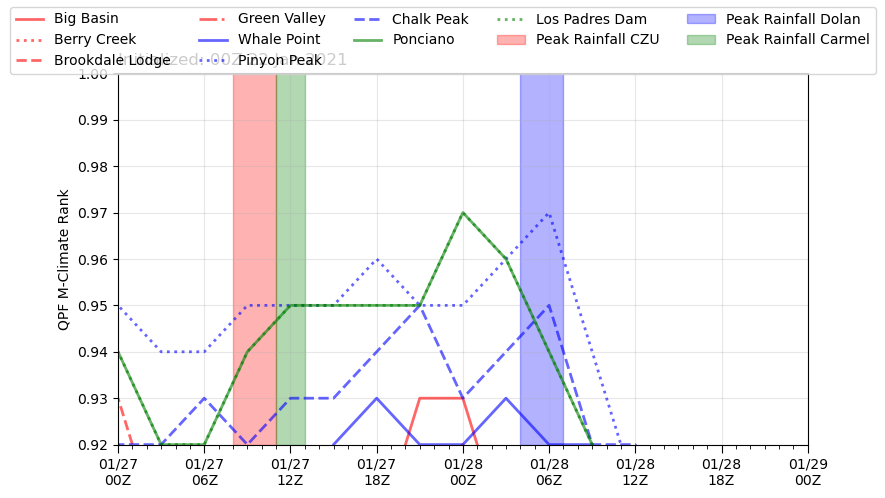

In [9]:
# ==========================================================
# Plot
# ==========================================================

fig, ax = plt.subplots(
    1,
    1,
    figsize=(8, 5)
)


for i, gauge in enumerate(rain_gauges.keys()):

    da = gauge_timeseries[gauge]

    times = pd.to_datetime(da.valid_time.values)

    values = da.values
    lbl = gauge.replace("_", " ")
    ax.plot(times, values, lw=2, label=lbl, color=colors[i], linestyle=linestyles[i], alpha=0.6)

    ax.set_ylabel("QPF M-Climate Rank")
    ax.grid(alpha=0.3)

# ==========================================================
# X-axis formatting
# ==========================================================

major_locator = mdates.HourLocator(byhour=[0, 6, 12, 18])
minor_locator = mdates.HourLocator(interval=1)

major_formatter = mdates.DateFormatter("%m/%d\n%HZ")

ax.xaxis.set_major_locator(major_locator)
ax.xaxis.set_minor_locator(minor_locator)
ax.xaxis.set_major_formatter(major_formatter)

ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)

ax.set_xlim(pd.to_datetime("2021-01-27 00"), pd.to_datetime("2021-01-29 00"))
ax.set_ylim(0.92, 1.)
ax.set_yticks(np.arange(0.92, 1.01, .01))

ax.axvspan(pd.to_datetime("2021-01-27 08"), pd.to_datetime("2021-01-27 11"), color='red', alpha=0.3, label='Peak Rainfall CZU')
ax.axvspan(pd.to_datetime("2021-01-28 04"), pd.to_datetime("2021-01-28 07"), color='blue', alpha=0.3, label='Peak Rainfall Dolan')
ax.axvspan(pd.to_datetime("2021-01-27 11"), pd.to_datetime("2021-01-27 13"), color='green', alpha=0.3, label='Peak Rainfall Carmel')


# title
date_obj = datetime.strptime(init_date, "%Y%m%d%H")
output_str = date_obj.strftime("%HZ %d %b %Y")
ax.set_title(f"Initialized: {output_str}", loc='left')

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig( f"figs/mclimate_time_series_{init_date}.png", dpi=300, bbox_inches="tight")